# TT-27 — RNN / LSTM / GRU: dự báo lưu lượng giao thông theo giờ

**Bài toán.** Sở Giao thông cần dự báo số xe qua nút giao 1–6 giờ tới để điều chỉnh chu kỳ đèn và cảnh báo ùn tắc.
Dữ liệu: lưu lượng theo giờ trên cao tốc I-94 (Minnesota, Mỹ), 2012–2018, kèm thời tiết và ngày lễ. Metric chính:
**MAE** (xe/giờ).

**Câu hỏi chính:** mạng hồi quy (SimpleRNN, LSTM, GRU) có thắng được hai baseline naive và XGBoost + lag không? Nếu
không thì kết luận trung thực là bài này không cần deep learning.

**Ba nguyên tắc chống rò rỉ** được kiểm tra trong code: (1) chia theo thời gian, không shuffle khi chia; (2) scaler fit
chỉ trên train; (3) cửa sổ chỉ chứa quá khứ (`assert` trong `sequences.make_windows`).

**Cách chạy.** Mỗi mạng nơ-ron lưu checkpoint + lịch sử + dự đoán vào `models/runs/`, nên chạy lại notebook **đọc lại**
thay vì train lại (~1,5 giờ trên CPU). Muốn train lại: đặt `TT27_RETRAIN=1`.

In [1]:
%matplotlib inline
import os, sys, warnings
from pathlib import Path
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path("..").resolve() / "src"))

import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import Image, display

import data as D
import sequences as S
import train as T

tf.config.experimental.enable_op_determinism()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.width", 200)
R = T.REPORTS_DIR

## 1–2. Làm sạch: 4 vấn đề dữ liệu và lỗ hổng thời gian

**Logic code (`data.clean`):**

```python
df.loc[df.temp == 0, "temp"] = NaN; df.loc[df.rain_1h > 1000, "rain_1h"] = NaN       # (2) ngoai lai phi ly
df = df.groupby("date_time").agg({..., "w_Rain": "max", "w_Drizzle": "max"})          # (3) gop dong trung
df = df.reindex(pd.date_range(min, max, freq="h"))                                     # (1) reindex theo gio
do_dai_lo = so gio NaN lien tiep
df[num] = df[num].interpolate().where(do_dai_lo <= 3)   # lo <= 3 gio: noi suy + co `noi_suy`; lo dai: giu NaN
df["holiday"] = ten le cua NGAY (lay tu dong 0h)                                       # (4) lan ra ca ngay
```

* Dòng trùng `date_time` có **cùng** `traffic_volume`, chỉ khác mô tả thời tiết (vd "Rain" và "Drizzle" cùng lúc).
  Gộp lại và one-hot thời tiết lấy max, nên giờ đó được đánh dấu cả mưa lẫn mưa phùn.
* Lỗ ≤ 3 giờ được nội suy (đánh dấu bằng cột `noi_suy` để model biết). Lỗ dài hơn để NaN, và chuỗi bị cắt ở đó:
  `sequences.valid_anchors` loại mọi cửa sổ chạm vào NaN.
* Nhãn dùng để train và đánh giá **chỉ lấy giờ có dữ liệu thật**, không lấy giờ nội suy.

In [2]:
data = T.load()
display(pd.read_csv(R / "van_de_du_lieu.csv", index_col=0))
display(data["split"])

[load] 48,204 dong goc -> 52,551 gio | mau h=1 train/val/test = 24,534/6,378/6,435


,so_luong
temp = 0 K (dong),10
rain_1h > 1000 mm (dong),1
dong trung date_time,7629
gio co > 1 gia tri traffic_volume,0
gio trong khoang 2012-10 -> 2018-09,52551
gio co du lieu,40575
gio thieu,11976
gio thieu trong lo <= 3 gio (noi suy),2771
gio thieu trong lo > 3 gio (de NaN),9205
so lo > 3 gio,136


,tu,den,so_gio,gio_co_gia_tri,so_mau_danh_gia_h1,luu_luong_tb
tap,,,,,,
train,2012-10-02 09:00:00,2017-04-06 10:00:00,39530,30342,24534,"3,282.08"
val,2017-04-06 11:00:00,2018-01-02 19:00:00,6513,6502,6378,"3,385.13"
test,2018-01-02 20:00:00,2018-09-30 23:00:00,6508,6502,6435,"3,325.90"


**Đọc kết quả:**

| Vấn đề | Số liệu | Xử lý |
|---|---|---|
| 1. Lỗ hổng | 52.551 giờ trong khoảng, chỉ 40.575 giờ có dữ liệu (**thiếu 11.976 giờ = 23%**). 2.771 giờ thiếu nằm trong lỗ ≤ 3 giờ, 9.205 giờ nằm trong 136 lỗ dài, lớn nhất **308 ngày** (08/2014 → 06/2015) | Nội suy lỗ ngắn, cắt chuỗi ở lỗ dài |
| 2. Ngoại lai | `temp = 0 K` 10 dòng, `rain_1h = 9.831 mm` 1 dòng | NaN rồi nội suy |
| 3. Trùng giờ | 7.629 dòng, **0** giờ có 2 giá trị lưu lượng khác nhau | Gộp, giữ cả 2 nhãn thời tiết |
| 4. Ngày lễ | 53 dòng ghi tên lễ | Lan ra **1.272 giờ** (53 ngày × 24) |

Chia 70/15/15 theo thời gian: train 2012-10 → 2017-04 (chứa cả lỗ 308 ngày), val 2017-04 → 2018-01, test
2018-01 → 2018-09. Sau khi loại cửa sổ chạm lỗ hổng và giờ nội suy, còn **24.534 / 6.378 / 6.435** mẫu cho dự báo 1 giờ.

## 3. EDA: lưu lượng theo giờ, thứ, tháng

**Logic code (`run_eda`):** `pivot_table(index=gio, columns=loai_ngay, values=traffic_volume, aggfunc=mean)` với loại
ngày = ngày thường / cuối tuần / ngày lễ. Biểu đồ dưới cùng là trung bình theo ngày cả 6 năm, với vùng đỏ là tỉ lệ giờ
thiếu trong ngày.

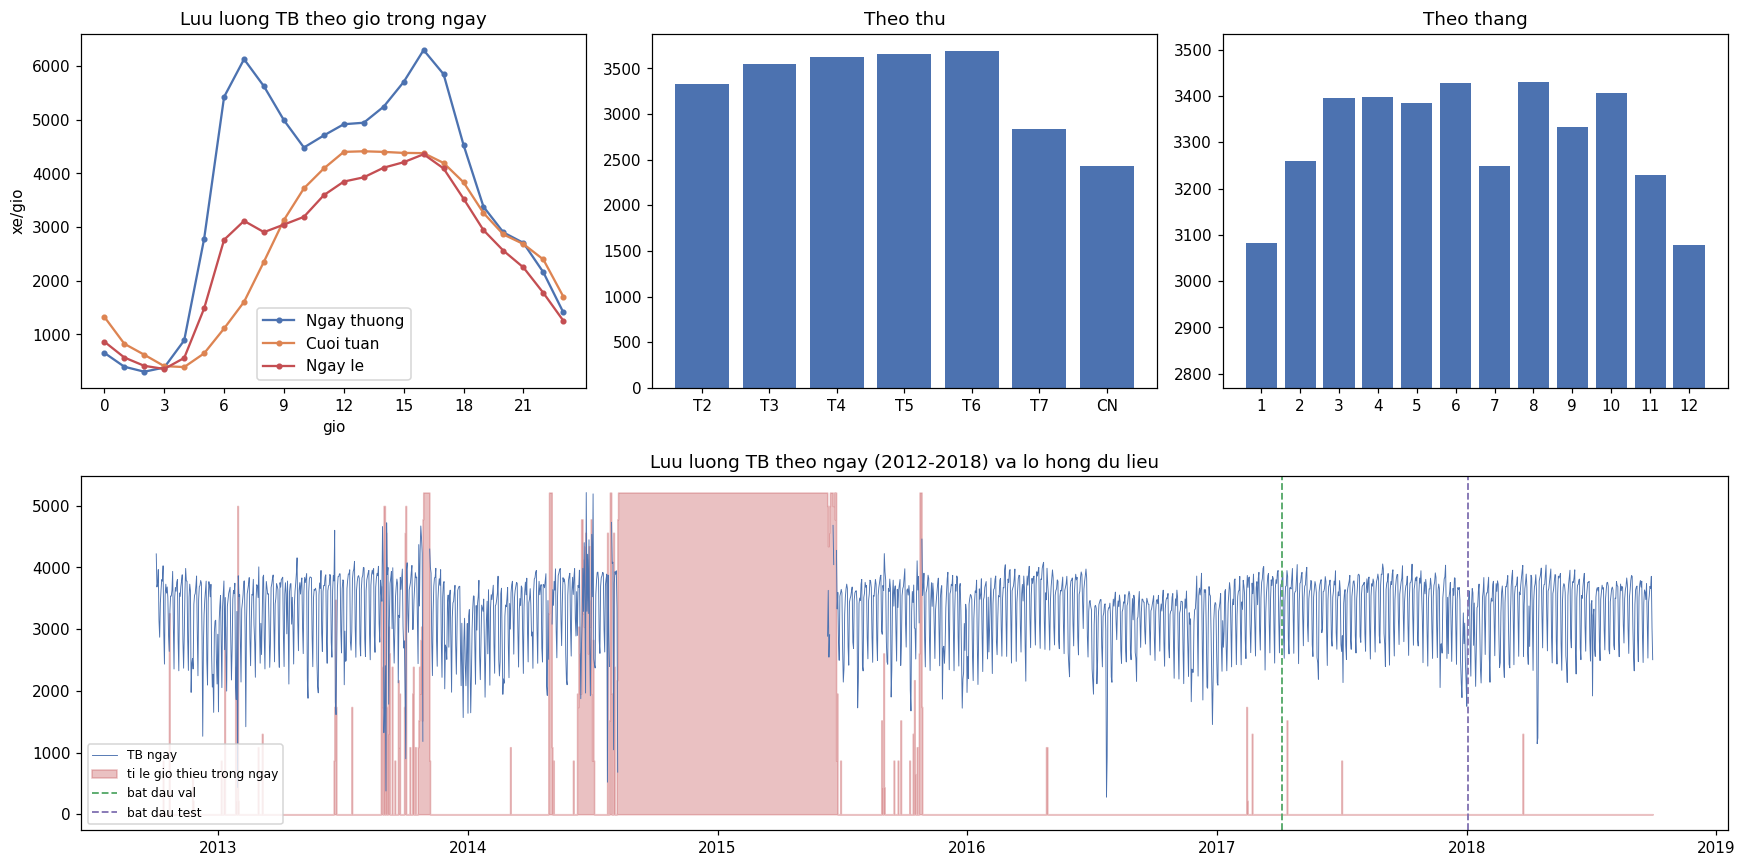

gio,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
loai_ngay,,,,,,,,,,,,,,,,,,,,,
Cuoi tuan,"1,326.00",825.00,621.00,409.00,391.00,647.00,"1,110.00","1,606.00","2,357.00","3,132.00",...,"4,400.00","4,381.00","4,377.00","4,194.00","3,834.00","3,262.00","2,862.00","2,684.00","2,396.00","1,705.00"
Ngay le,864.00,570.00,414.00,357.00,561.00,"1,484.00","2,763.00","3,115.00","2,905.00","3,046.00",...,"4,106.00","4,208.00","4,357.00","4,092.00","3,529.00","2,943.00","2,559.00","2,248.00","1,774.00","1,256.00"
Ngay thuong,656.00,398.00,305.00,383.00,888.00,"2,782.00","5,424.00","6,128.00","5,621.00","4,990.00",...,"5,243.00","5,703.00","6,297.00","5,848.00","4,530.00","3,379.00","2,900.00","2,705.00","2,158.00","1,412.00"


In [3]:
eda = T.run_eda(data)
display(Image(R / "eda_theo_gio.png"))
display(eda["theo_gio"].round(0).T)

**Đọc kết quả:**

* **Chu kỳ ngày:** ngày thường có **2 đỉnh** (7h ≈ 6.100 và 16h ≈ 6.300 xe/giờ: giờ đi làm và giờ tan tầm), đáy ≈ 300 lúc
  2–3h sáng. Cuối tuần chỉ có **1 bình nguyên** 12h–16h ≈ 4.400.
* **Ngày lễ giống cuối tuần**, không giống ngày thường, nên cờ `holiday` (đã lan ra cả ngày) rất quan trọng: không có nó
  model sẽ dự báo đỉnh 7h cho ngày 4/7.
* **Chu kỳ tuần:** T2–T6 ≈ 3.300–3.700, T7 ≈ 2.800, CN ≈ 2.400. T2 thấp hơn T3–T6 một chút.
* **Theo tháng** chênh ít (≈ 3.100–3.400), thấp nhất tháng 1 và 12 (mùa đông, tuyết).
* Biểu đồ dưới: ngoài lỗ 308 ngày, 2013–2015 có nhiều lỗ rải rác. Val/test (từ 04/2017) gần như liên tục.

## 4–5. Đặc trưng và cửa sổ trượt

**Logic code (`data.add_features`, `sequences.make_windows`):**

```python
# moi gio: traffic, temp_c, log1p(rain), co tuyet, may, one-hot thoi tiet (10), noi_suy,
#          sin/cos(2*pi*gio/24), sin/cos(2*pi*thu/7), cuoi_tuan, ngay_le                    -> 22 cot
# moc a = gio cuoi cung da biet. Du bao gio a+h.
X    = bang_chuan_hoa[a-w+1 : a+1]                       # (w, 22): chi QUA KHU
side = [lich cua gio a+h (6 cot), y[a+h-24], y[a+h-168]] # thong tin BIET TRUOC ve gio can du bao
y    = traffic[a+h]
```

* **sin/cos** để 23h và 0h nằm cạnh nhau (với số nguyên 0..23 thì chúng cách nhau 23 đơn vị).
* **Thông tin biết trước (`side`):** lịch của giờ cần dự báo là biết trước. Lưu lượng cùng giờ hôm qua và tuần trước
  là quá khứ (h ≤ 6 < 24). Cửa sổ 24–48 giờ không "nhìn" tới tuần trước được, nên đưa thẳng giá trị đó vào. XGBoost
  cũng nhận đúng các thông tin này, để so sánh công bằng.
* **Tập mẫu dùng chung:** `valid_anchors` chọn các mốc có đủ 48 giờ quá khứ liền mạch + giá trị tuần trước + nhãn thật.
  Mọi mô hình và mọi độ dài cửa sổ được đánh giá trên **đúng cùng các giờ**.
* Hàm `tao_chuoi` của đề vẫn có trong `sequences.py` để đối chiếu, nhưng không dùng: nó coi chuỗi là liên tục, nên ở chỗ
  lỗ 308 ngày một cửa sổ sẽ ghép 06/08/2014 với 11/06/2015.

In [4]:
w = T.windows(data, "train", 24, 1)
print("X:", w.X.shape, "| side:", w.side.shape, "| y:", w.y.shape)
print("Cot dau vao:", list(data["feat_s"].columns))
print("Mau dau tien: cua so", w.t[0] - pd.Timedelta(hours=24), "->", w.t[0] - pd.Timedelta(hours=1), "| nhan", w.t[0])
print("Scaler fit tren train: TB traffic =", round(data["scaler"].mu), "| do lech chuan =", round(data["scaler"].sd))

X: (24534, 24, 22) | side: (24534, 8) | y: (24534,)
Cot dau vao: ['traffic_volume', 'temp_c', 'rain_log', 'snow', 'clouds', 'w_Clear', 'w_Clouds', 'w_Mist', 'w_Rain', 'w_Snow', 'w_Drizzle', 'w_Haze', 'w_Thunderstorm', 'w_Fog', 'w_Other', 'noi_suy', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'weekend', 'holiday']
Mau dau tien: cua so 2012-10-08 10:00:00 -> 2012-10-09 09:00:00 | nhan 2012-10-09 10:00:00
Scaler fit tren train: TB traffic = 3282 | do lech chuan = 1976


## 6. ⭐ Hai baseline naive

```python
naive          = y[t - 24]     # gio nay = gio nay hom qua
seasonal_naive = y[t - 168]    # gio nay = gio nay tuan truoc
```

Không cần train. Mọi mô hình phải thắng **seasonal naive** mới có giá trị.

In [5]:
pd.DataFrame(T.baselines(data, 1))

,mo_hinh,h,mae_val,rmse_val,mae_test,rmse_test
0,Naive (cung gio hom qua),1,549.33,"1,009.53",558.45,"1,020.09"
1,Seasonal naive (cung gio tuan truoc),1,300.56,578.60,337.64,647.42


**Đọc kết quả:**

| | MAE val | MAE test |
|---|---:|---:|
| Naive (hôm qua) | 549 | 558 |
| **Seasonal naive (tuần trước)** | **301** | **338** |

Seasonal naive tốt gần gấp đôi naive, vì "hôm qua" sai hoàn toàn ở thứ 2 (hôm qua là CN) và thứ 7 (hôm qua là T6),
còn "tuần trước" luôn cùng loại ngày. Đây là vạch xuất phát thật sự.

## 7. Baseline cây: XGBoost + lag

**Logic code (`run_xgb`, `sequences.tree_matrix`):**

```python
X = [y[a], y[a-1], ..., y[a-23],          # 24 lag gan nhat
     y[a+h-24], y[a+h-168], TB 3 gio,     # cung gio hom qua / tuan truoc
     thoi tiet tai a, gio/thu/thang/le cua gio a+h]
XGBRegressor(n_estimators=3000, learning_rate=0.03, max_depth=7, subsample=0.8,
             early_stopping_rounds=100, eval_metric="mae").fit(X_train, y_train, eval_set=[(X_val, y_val)])
```

In [6]:
xgbs = {h: T.run_xgb(data, h) for h in T.HORIZONS}
print("Do quan trong (gain), h=1:")
xgbs[1]["importance"].head(10).to_frame("importance")

[xgb h=1] 892 cay, 28.9s | MAE val 147.2 test 142.1


[xgb h=3] 1269 cay, 48.1s | MAE val 188.3 test 181.7


[xgb h=6] 817 cay, 28.2s | MAE val 199.0 test 200.3


Do quan trong (gain), h=1:


,importance
cung_gio_tuan_truoc,0.60
gio_dich,0.13
lag_0,0.12
cung_gio_hom_qua,0.02
le_dich,0.02
lag_23,0.01
tb_3_gio,0.01
lag_20,0.01
lag_18,0.01
thu_dich,0.01


**Đọc kết quả:** XGBoost đạt **MAE val 147 / test 142** cho 1 giờ tới, chỉ trong **16 giây**. Thấp hơn nhiều so với mức
tham chiếu 250–400 của đề, và bằng 42% seasonal naive.

Độ quan trọng: **cùng giờ tuần trước 60%**, giờ đích 13%, **lưu lượng giờ hiện tại (`lag_0`) 12%**, cùng giờ hôm qua 2%,
ngày lễ 2%. Tức là model học "lấy mẫu hình tuần trước, rồi chỉnh theo mức hiện tại". Thời tiết gần như không xuất hiện
trong top 10, vì ảnh hưởng của thời tiết đã thể hiện trong lưu lượng các giờ vừa qua.

## 8. SimpleRNN vs LSTM vs GRU

**Logic code (`build_rnn`, `fit_seq`):**

```python
x = Layer(64, return_sequences=True)(cua_so)   # Layer = SimpleRNN | LSTM | GRU ; tra ca chuoi cho lop sau
x = Dropout(0.2)(x)
x = Layer(32)(x)                               # lop cuoi: chi trang thai cuoi cung
x = Dropout(0.2)(x)
x = Concatenate()([x, biet_truoc]) -> Dense(32, relu)
out = Dense(1)                                 # KHONG activation: hoi quy
compile(Adam(1e-3), loss="mse", metrics=["mae"]); batch 256, toi da 60 epoch
EarlyStopping(val_loss, patience=8, restore_best_weights) + ReduceLROnPlateau(val_loss, 0.5, patience=4)
```

Cùng cửa sổ 24 giờ, cùng seed, cùng tập mẫu. Thêm **LSTM chỉ dùng cửa sổ** (đúng như mô hình trong đề, không có nhánh
thông tin biết trước) để đo nhánh đó có giúp không. `fit(..., shuffle=True)` xáo trộn các **cửa sổ** đã tạo. Việc này
được phép vì thứ tự thời gian đã nằm *bên trong* mỗi cửa sổ.

,mo_hinh,h,tham_so,so_epoch,thoi_gian_train_s,mae_val,mae_test,rmse_val,rmse_test
0,SimpleRNN w=24 h=1,1,"10,017.00",58.00,243.20,160.41,154.16,242.24,232.08
1,LSTM w=24 h=1,1,"36,033.00",46.00,463.90,164.11,161.76,249.12,244.03
2,GRU w=24 h=1,1,"27,649.00",60.00,536.60,152.08,147.30,229.90,220.96
3,LSTM w=24 h=1 (chi cua so),1,"34,721.00",59.00,440.90,154.92,149.07,238.87,225.63
4,Naive (cung gio hom qua),1,NaN,NaN,NaN,549.33,558.45,"1,009.53","1,020.09"
5,Seasonal naive (cung gio tuan truoc),1,NaN,NaN,NaN,300.56,337.64,578.60,647.42
6,XGBoost + lag,1,NaN,NaN,28.87,147.22,142.06,230.21,221.82


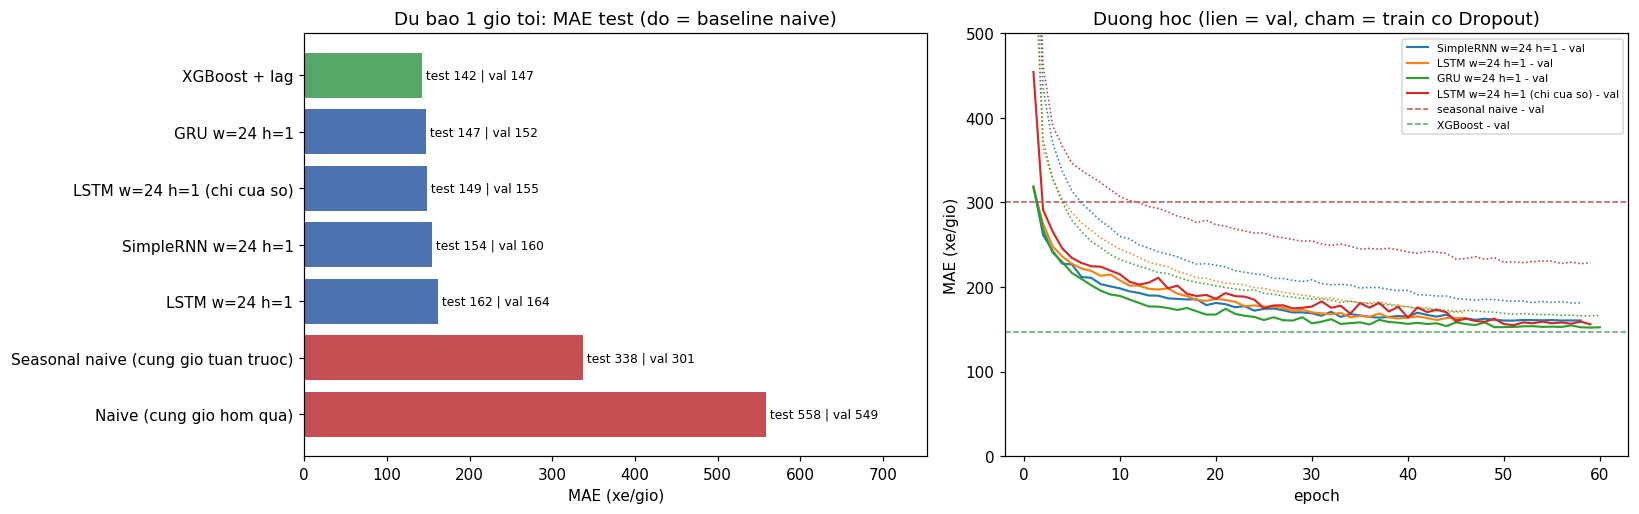

In [7]:
table, runs = T.run_rnn_lstm_gru(data, xgbs[1])
display(table)
display(Image(R / "rnn_lstm_gru.png"))

**Đọc kết quả (1 giờ tới, cửa sổ 24h):**

| | Tham số | Epoch | Thời gian | MAE val | MAE test |
|---|---:|---:|---:|---:|---:|
| SimpleRNN | 10.017 | 58 | 4 ph | 160 | 154 |
| LSTM | 36.033 | 46 | 8 ph | 164 | 162 |
| **GRU** | 27.649 | 60 | 9 ph | **152** | **147** |
| LSTM chỉ cửa sổ | 34.721 | 59 | 7 ph | 155 | 149 |
| Seasonal naive | — | — | — | 301 | 338 |
| **XGBoost + lag** | — | — | **16 s** | **147** | **142** |

* ✅ **Cả 4 mạng đều thắng seasonal naive rất rõ** (MAE ~150–160 so với 301 / 338, giảm ~50%).
* **GRU tốt nhất trong các mạng** nên được chọn cho các bước sau. Thứ tự LSTM < SimpleRNN là bất ngờ: cửa sổ chỉ có 24
  bước, ngắn, nên lợi thế "ký ức dài" của LSTM chưa có đất dùng. Vanishing gradient của SimpleRNN thành vấn đề khi phụ
  thuộc xa hơn khoảng 10 bước, nhưng ở đây giờ quan trọng nhất là giờ vừa qua.
* **Nhánh thông tin biết trước không giúp LSTM** (164 có so với 155 không có). Một lý do: với cửa sổ 24h, giá trị "cùng
  giờ hôm qua" đã nằm trong cửa sổ. Nhưng bước "dao động theo seed" bên dưới cho thấy chênh lệch giữa các seed là ~5, nên
  chênh 9 điểm này chỉ có thể kết luận "không giúp", chưa thể kết luận "có hại".
* **XGBoost vẫn thắng** mọi mạng, và nhanh hơn GRU **~34 lần** (16 s so với 9 phút).
* Đường học: MAE train (chấm) **cao hơn** val vì train được đo khi Dropout đang bật. GRU chạm trần 60 epoch (SimpleRNN
  dừng ở 58) khi val chỉ còn giảm rất chậm, nên train lâu hơn khó đổi kết luận.

## 9. Khảo sát độ dài cửa sổ: 6 / 12 / 24 / 48 giờ

Dùng GRU (kiểu tốt nhất theo val), dự báo 1 giờ tới, cùng tập mẫu.

,cua_so_gio,mo_hinh,h,tham_so,so_epoch,thoi_gian_train_s,mae_val,mae_test,rmse_val,rmse_test
0,6,GRU w=6 h=1,1,27649,60,114.20,157.31,152.91,235.10,228.34
1,12,GRU w=12 h=1,1,27649,52,232.00,155.12,149.30,233.70,223.01
2,24,GRU w=24 h=1,1,27649,60,536.60,152.08,147.30,229.90,220.96
3,48,GRU w=48 h=1,1,27649,60,"1,235.80",153.50,148.58,231.27,222.46


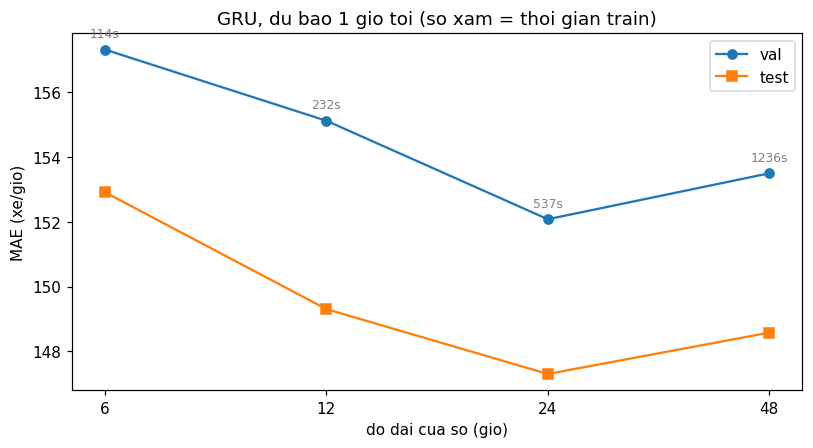

In [8]:
kind = T.best_kind(runs)
win_table, wins = T.run_windows(data, kind, runs[kind])
display(win_table)
display(Image(R / "do_dai_cua_so.png"))

**Đọc kết quả:**

| Cửa sổ | Thời gian | MAE val | MAE test |
|---:|---:|---:|---:|
| 6h | 2 ph | 157 | 153 |
| 12h | 4 ph | 155 | 149 |
| **24h** | 9 ph | **152** | **147** |
| 48h | 21 ph | 153 | 149 |

* MAE gần như **phẳng**: 6h → 24h chỉ giảm 5, 24h → 48h tăng lại 1. Chênh lệch nằm trong khoảng dao động do seed (~5).
* Thời gian train tăng **gần tuyến tính** theo độ dài cửa sổ (48h chậm gấp 11 lần 6h). Cửa sổ dài không tốt hơn, đúng
  với cạm bẫy "cửa sổ quá dài" của đề.
* Lý do cửa sổ ngắn đã đủ: mẫu hình ngày và tuần đã có trong nhánh thông tin biết trước (lịch + cùng giờ tuần trước),
  còn cửa sổ chỉ cần cho biết **mức lưu lượng hiện tại** so với mẫu hình, và vài giờ gần nhất là đủ.

## Thêm: dao động theo seed

Train lại GRU cửa sổ 24h với seed 1 và 2: chênh lệch giữa các cấu hình ở trên có lớn hơn nhiễu không?

In [9]:
window = int(win_table.loc[win_table["mae_val"].idxmin(), "cua_so_gio"])
best = wins[window]
seeds = T.run_seeds(data, kind, window, best)
display(seeds)
print(f"MAE test: {seeds.mae_test.mean():.1f} +- {seeds.mae_test.std():.1f} | XGBoost: {xgbs[1]['mae_test']:.1f}")

,seed,mo_hinh,h,tham_so,so_epoch,thoi_gian_train_s,mae_val,mae_test,rmse_val,rmse_test
0,42,GRU w=24 h=1,1,27649,60,536.60,152.08,147.30,229.90,220.96
1,1,GRU w=24 h=1,1,27649,57,467.00,152.55,148.14,233.37,226.23
2,2,GRU w=24 h=1,1,27649,55,385.40,157.09,153.01,235.84,227.63


MAE test: 149.5 +- 3.1 | XGBoost: 142.1


**Đọc kết quả:** GRU 24h qua 3 seed: MAE val **153,9 ± 2,8**, test **149,5 ± 3,1** (147,3 / 148,1 / 153,0).

* Mọi chênh lệch giữa cửa sổ 6–48h (≤ 5) và giữa GRU / SimpleRNN / LSTM-chỉ-cửa-sổ (≤ 8) đều cùng cỡ với dao động seed
  (khoảng 6 giữa seed tốt nhất và kém nhất). Chỉ "LSTM có nhánh phụ" là rõ ràng kém hơn.
* **XGBoost (142,1) thấp hơn cả seed tốt nhất của GRU (147,3)**, nên đây không phải may rủi: XGBoost thắng thật, dù chỉ
  ~5% MAE.

## 10. Dự báo vs thực tế: tuần cuối tập test

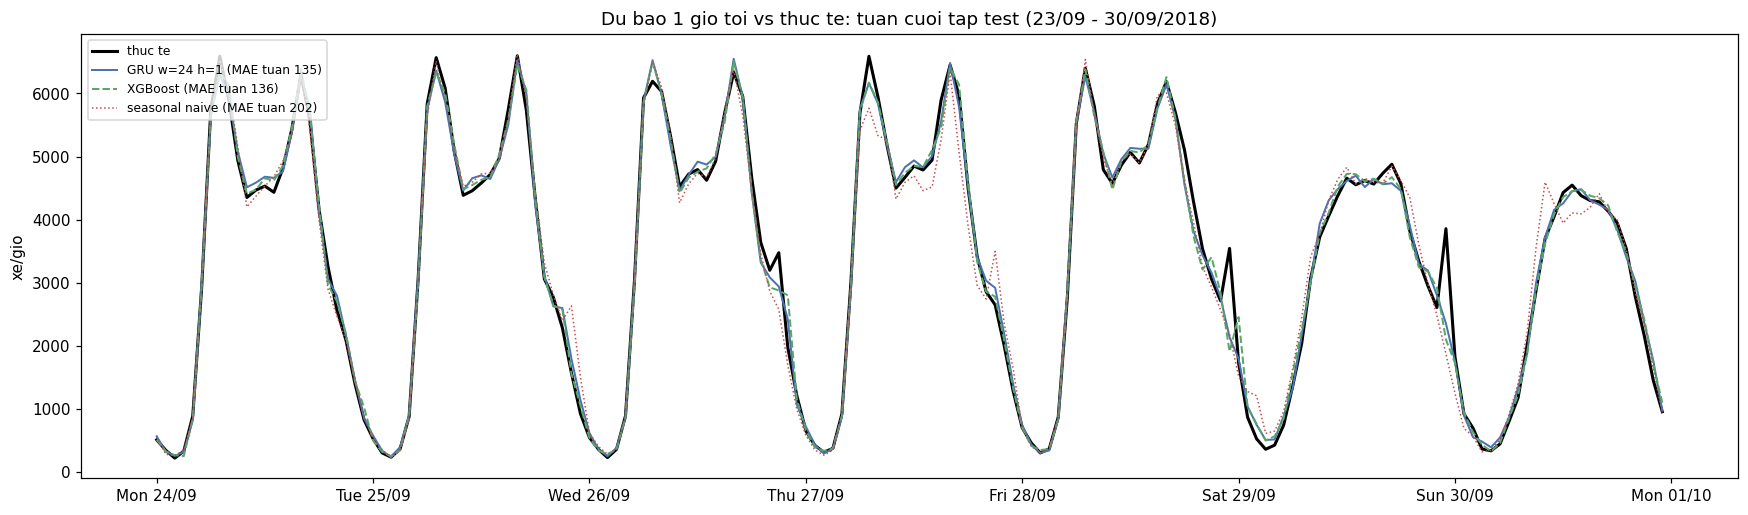

In [10]:
T.plot_week(data, best, xgbs[1])
display(Image(R / "du_bao_vs_thuc_te.png"))

**Đọc kết quả (23/09 – 30/09/2018):** GRU và XGBoost gần như **trùng nhau** và bám sát thực tế (MAE tuần 135 / 136),
kể cả hai đỉnh mỗi ngày thường và bình nguyên cuối tuần. Seasonal naive (MAE tuần 202) lệch ở những chỗ tuần này khác
tuần trước. Cả ba đều **không bắt được đột biến** như đỉnh 22–23h tối thứ 7 (29/09): mô
hình 1 giờ tới chỉ phản ứng **sau khi** đột biến đã bắt đầu.

## 11. Dự báo nhiều bước: 1h / 3h / 6h tới

Train riêng một GRU (cửa sổ 24h) và một XGBoost cho mỗi tầm dự báo h. Nhãn là `y[a+h]`, đầu vào vẫn chỉ đến giờ `a`.

mae_val               mae_test              
h                                          1      3      6        1      3      6
mo_hinh_goc                                                                      
Naive (cung gio hom qua)              549.33 549.04 548.61   558.45 557.71 557.81
Seasonal naive (cung gio tuan truoc)  300.56 299.94 299.53   337.64 337.68 337.77
XGBoost + lag                         147.22 188.27 199.01   142.06 181.68 200.32
GRU w=24                              152.08 200.85 204.67   147.30 201.45 214.97

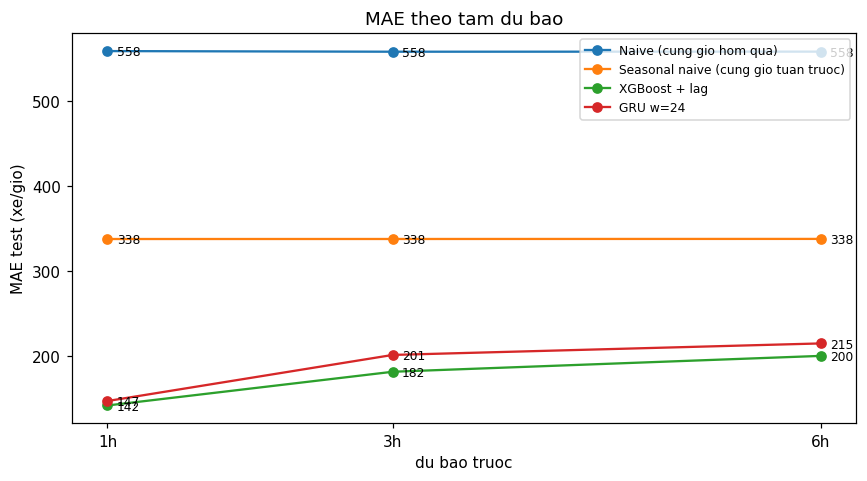

In [11]:
multi, _ = T.run_multistep(data, kind, window, best, xgbs)
display(multi.pivot_table(index="mo_hinh_goc", columns="h", values=["mae_val", "mae_test"], sort=False))
display(Image(R / "du_bao_nhieu_buoc.png"))

**Đọc kết quả (MAE test, xe/giờ):**

| | 1h | 3h | 6h | Tăng 1h → 6h |
|---|---:|---:|---:|---:|
| Naive (hôm qua) | 558 | 558 | 558 | 0 |
| Seasonal naive | 338 | 338 | 338 | 0 |
| **XGBoost + lag** | **142** | **182** | **200** | +41% |
| GRU 24h | 147 | 201 | 215 | +46% |

* Hai baseline naive **không đổi theo h**: "cùng giờ tuần trước" không phụ thuộc vào việc dự báo trước bao lâu.
* Mô hình học máy xấu đi khi h tăng, vì thông tin "lưu lượng hiện tại" cũ dần. Bước nhảy lớn nhất là 1h → 3h (+28% với
  XGBoost, +37% với GRU), sau đó chậm lại. Ở 6h tới, cả hai vẫn chỉ bằng **~60%** sai số của seasonal naive.
* **Khoảng cách XGBoost – GRU rộng ra** khi h tăng (5 → 19 → 15). Ở 3h, GRU kém XGBoost 11%.

## 12. Phân tích lỗi: sai nhiều nhất vào giờ nào, ngày nào?

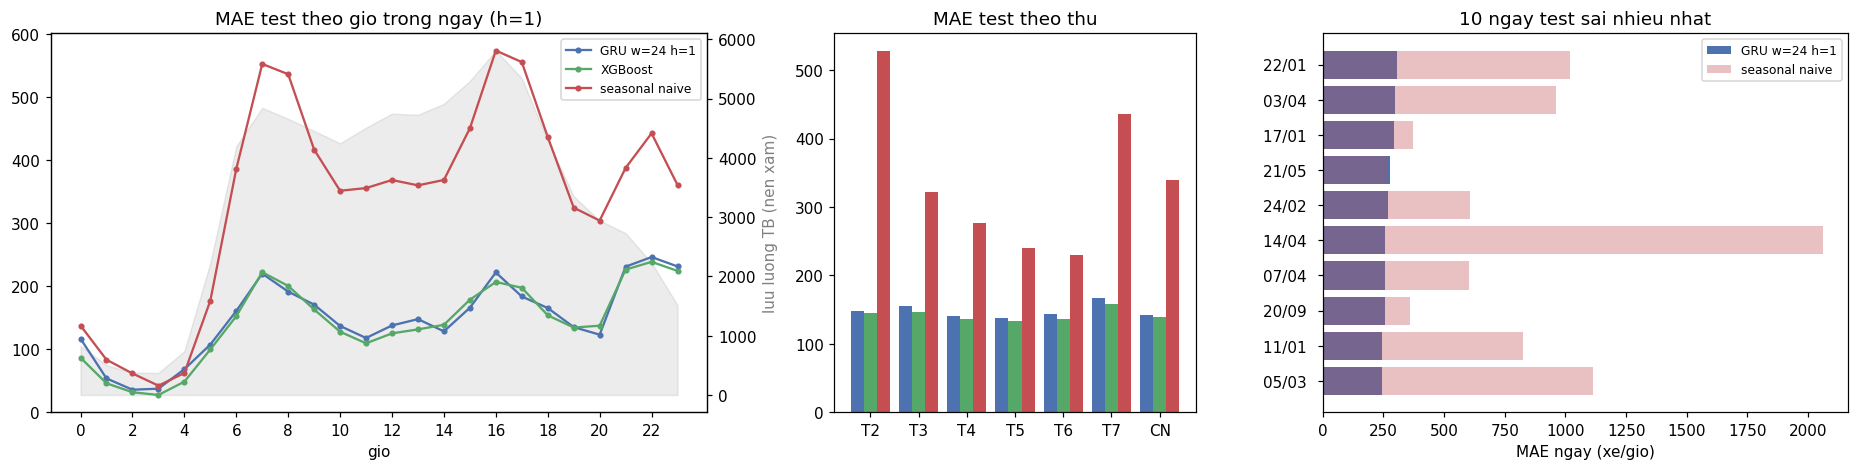

err_nn       err_xgb         err_sn      
        mean  size    mean  size     mean  size
le                                             
False 146.72  6292  141.79  6292   319.64  6292
True  172.81   143  154.00   143 1,129.59   143

,mae_nn,mae_sn,luu_luong_tb,so_gio,thu,ngay_le
t,,,,,,
2018-01-22,306.87,"1,020.21","2,126.50",24,Monday,None
2018-04-03,297.53,963.08,"2,718.92",24,Tuesday,None
2018-01-17,294.62,371.75,"3,368.96",24,Wednesday,None
2018-05-21,278.96,265.71,"3,449.25",24,Monday,None
2018-02-24,268.83,607.04,"2,401.42",24,Saturday,None
2018-04-14,257.89,"2,060.92","1,143.92",24,Saturday,None
2018-04-07,256.71,602.38,"3,204.83",24,Saturday,None
2018-09-20,256.70,360.42,"3,478.33",24,Thursday,None
2018-01-11,246.29,823.38,"2,736.71",24,Thursday,None


,t,y,nn,err_nn,sn
3261,2018-05-21 13:00:00,"2,040.00","4,848.49","2,808.49","4,831.00"
355,2018-01-17 15:00:00,"3,271.00","5,647.22","2,376.22","5,681.00"
4254,2018-07-01 23:00:00,"3,078.00","1,510.05","1,567.95","1,209.00"
6002,2018-09-12 23:00:00,"2,842.00","1,280.77","1,561.23",993.00
6410,2018-09-29 23:00:00,"3,856.00","2,353.48","1,502.52","1,871.00"
1482,2018-03-05 16:00:00,"3,260.00","4,750.47","1,490.47","6,370.00"
5978,2018-09-11 23:00:00,"2,682.00","1,199.41","1,482.59",921.00
1678,2018-03-13 22:00:00,"3,761.00","2,284.29","1,476.71","2,587.00"
363,2018-01-17 23:00:00,"2,597.00","1,180.16","1,416.84","1,115.00"
5307,2018-08-14 23:00:00,"2,772.00","1,360.32","1,411.68","1,168.00"


[save] gru_w24_h1 -> models/lstm_traffic.keras


[save] reports/tom_tat.json


In [12]:
err = T.run_error_analysis(data, best, xgbs[1])
display(Image(R / "phan_tich_loi.png"))
display(err["theo_ngay_le"])
display(err["ngay_sai"])
display(err["gio_sai"])
T.save_final_model(best, data)
T.save_summary(van_de=pd.read_csv(R / "van_de_du_lieu.csv"), chia=data["split"], rnn_lstm_gru=table, kieu_chon=kind,
               cua_so_chon=window, cua_so=win_table, seed=seeds, nhieu_buoc=multi,
               xgb_importance=xgbs[1]["importance"].head(15))

**Đọc kết quả (GRU, 1 giờ tới, tập test):**

* **Theo giờ:** sai số lớn nhất ở **hai đỉnh** (7h ≈ 220, 16h ≈ 222) và bất ngờ là **21–23h (≈ 230–246)** dù lúc đó
  lưu lượng chỉ bằng 1/2 đến 1/4 giờ cao điểm. Tính theo tỉ lệ, buổi tối là lúc khó nhất. 10/15 giờ sai nhiều nhất của
  test là **tăng đột biến lúc 21–23h** (vd 23h ngày 29/09: thực tế 3.856 so với dự báo 2.353). Đây có thể là sự kiện,
  phân luồng hoặc đóng đường ban đêm, những thông tin không có trong dữ liệu.
* **Theo thứ:** GRU và XGBoost đều đều 134–166 mọi ngày. Seasonal naive sai nặng nhất thứ 2 (527) và thứ 7 (436).
  Test có **4/6 ngày lễ rơi vào thứ 2** (MLK Day 15/01, Washington's Birthday 19/02, Memorial Day 28/05, Labor Day
  03/09). Seasonal naive sai **hai lần** mỗi lễ: chính ngày lễ (tuần trước là ngày thường) và thứ 2 tuần sau (tuần trước
  là ngày lễ). Thứ 7 có 3 ngày tuyết lớn (24/02, 07/04, 14/04).
* **10 ngày sai nhiều nhất: 7/10 là ngày có tuyết 13–23 giờ** (22/01, 03/04, 24/02, 14/04, 07/04, 11/01, 05/03). Ngày
  14/04/2018 có tuyết 23 giờ, lưu lượng TB chỉ 1.144 xe/giờ so với 3.204 cùng ngày tuần trước. Seasonal naive sai
  2.061/giờ, GRU chỉ sai 258, vì GRU thấy lưu lượng mấy giờ vừa qua đã giảm.
* Hai giờ sai nặng nhất là **sụt giảm giữa ngày**: 21/05 13h (thực tế 2.040, dự báo 4.848) và 17/01 15h. Đây là kiểu sự
  cố (tai nạn, đóng làn) không dự báo trước được từ lịch sử.

→ Muốn giảm sai số thêm, cần **dữ liệu mới** (dự báo thời tiết cho giờ tới, lịch sự kiện, sự cố giao thông), không phải
mô hình phức tạp hơn.

## Kết luận

1. ✅ **Mạng hồi quy thắng seasonal naive rất rõ:** GRU MAE test 147 (3 seed: 149,5 ± 3,1) so với 338, giảm 56%.
2. ❌ **Nhưng không thắng XGBoost + lag:** 142 ở 1h, 182 ở 3h, 200 ở 6h, tốt hơn GRU ở mọi tầm dự báo, train trong
   **16 giây** so với **9 phút** (nhanh hơn ~34 lần), không cần chuẩn hoá hay cắt cửa sổ.
3. **Kết luận trung thực:** với bài này, **triển khai XGBoost + lag features**. Deep learning không cần thiết: độ chính
   xác bằng hoặc kém hơn, chi phí cao hơn nhiều. GRU đáng thử khi có nhiều chuỗi liên quan (nhiều nút giao), hoặc cần
   dự báo cả chuỗi 24 giờ cùng lúc (Seq2Seq).
4. Trong các mạng: **GRU ≥ SimpleRNN ≈ LSTM** với cửa sổ ngắn. Cửa sổ 12–48h như nhau, chỉ khác thời gian train.
5. Sai số lớn nhất đến từ **tuyết** và **đột biến buổi tối / sự cố**, những thứ không nằm trong lịch sử lưu lượng.